<a href="https://colab.research.google.com/github/dimassatrio1209-cmd/pabw-muhammaddimassatriodomargo/blob/main/TugasKelompokLinearDanLogisticRegression_FSD.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Tugas Kelompok: Linear Regression dan Logistic Regression
**Anggota Kelompok:**
1. Muhammad Dimas Satrio Domargo (25523262)
2. Abi Manyu Maheswara Ghoevara (25523084)
3. Pradhipta Widya Satria(23523129)

## A1. Deskripsi Dataset
* **Asal Dataset:** Dataset bawaan dari library `seaborn` bernama `tips`.
* **Jumlah Baris dan Kolom:** 244 baris dan 7 kolom.
* **Arti Fitur:** `total_bill` (total tagihan), `sex` (jenis kelamin pembayar), `smoker` (perokok/bukan), `day` (hari), `time` (waktu makan), `size` (jumlah rombongan).
* **Variabel Target:** `tip` (jumlah tip yang diberikan, numerik kontinu).

Statistik Deskriptif:
        total_bill         tip        size
count  244.000000  244.000000  244.000000
mean    19.785943    2.998279    2.569672
std      8.902412    1.383638    0.951100
min      3.070000    1.000000    1.000000
25%     13.347500    2.000000    2.000000
50%     17.795000    2.900000    2.000000
75%     24.127500    3.562500    3.000000
max     50.810000   10.000000    6.000000


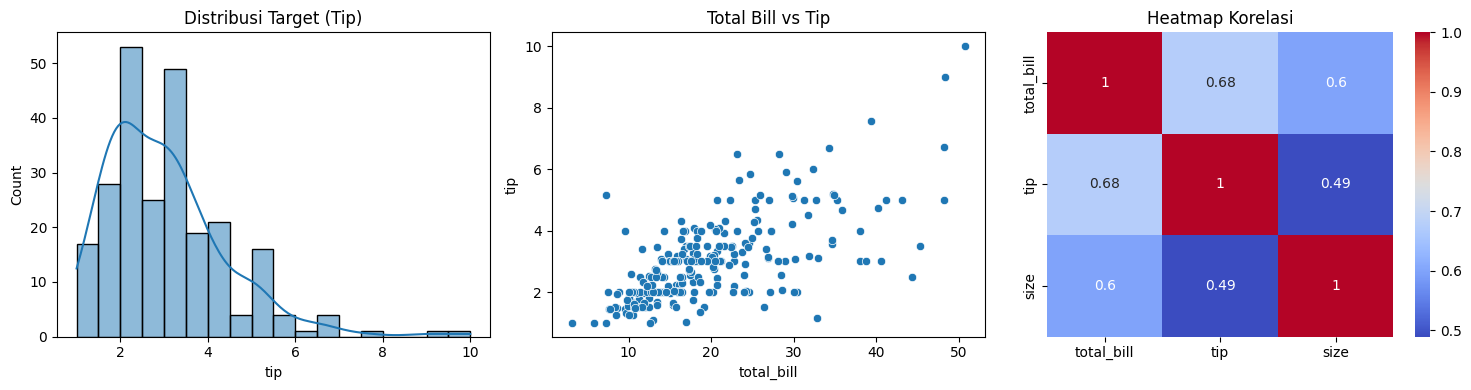


--- Model Linear Regression ---
Intercept: 2.999390417076214
         Fitur  Koefisien
0   total_bill   0.760087
1         size   0.200523
2   sex_Female  -0.018162
3    smoker_No   0.052130
4      day_Fri   0.049832
5      day_Sat   0.153115
6      day_Sun   0.217614
7  time_Dinner  -0.194669

--- Evaluasi Model ---
Train - RMSE: 0.99, R2: 0.45
Test  - RMSE: 1.08, R2: 0.52


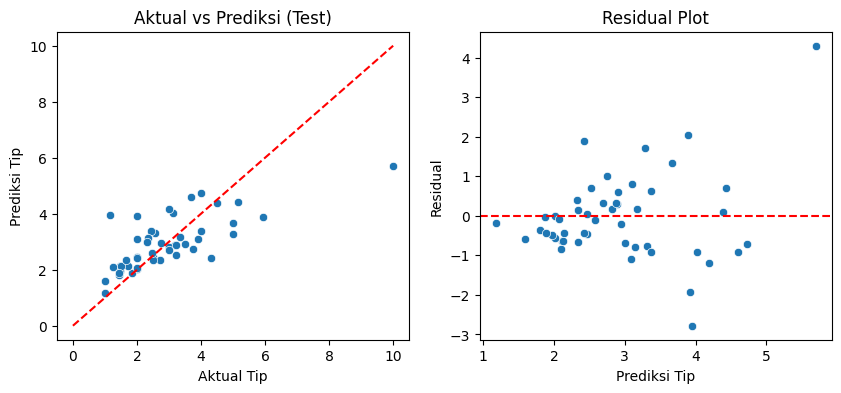

In [1]:
# Import Library yang dibutuhkan
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler

# A2. Eksplorasi dan Visualisasi Data
df_tips = sns.load_dataset('tips')
print("Statistik Deskriptif:\n", df_tips.describe())

plt.figure(figsize=(15, 4))
# 1. Histogram target
plt.subplot(1, 3, 1)
sns.histplot(df_tips['tip'], kde=True)
plt.title('Distribusi Target (Tip)')

# 2. Scatter plot fitur utama vs target
plt.subplot(1, 3, 2)
sns.scatterplot(x='total_bill', y='tip', data=df_tips)
plt.title('Total Bill vs Tip')

# 3. Heatmap korelasi (hanya numerik)
plt.subplot(1, 3, 3)
sns.heatmap(df_tips.select_dtypes(include=np.number).corr(), annot=True, cmap='coolwarm')
plt.title('Heatmap Korelasi')
plt.tight_layout()
plt.show()

# A3. Preprocessing
# Mengecek missing value dan duplikat
df_tips = df_tips.drop_duplicates()
# Encoding categorical data (One-Hot Encoding)
df_tips_encoded = pd.get_dummies(df_tips, drop_first=True)

# A4. Pemilihan Fitur
# Memilih semua fitur yang telah di-encode karena jumlahnya sedikit dan relevan.
X = df_tips_encoded.drop('tip', axis=1)
y = df_tips_encoded['tip']

# Scaling fitur numerik (opsional tapi baik untuk linear regression)
scaler = StandardScaler()
X[['total_bill', 'size']] = scaler.fit_transform(X[['total_bill', 'size']])

# A5. Pembagian Data (80:20)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# A6. Pemodelan
model_lin = LinearRegression()
model_lin.fit(X_train, y_train)
print("\n--- Model Linear Regression ---")
print("Intercept:", model_lin.intercept_)
coef_df = pd.DataFrame({'Fitur': X.columns, 'Koefisien': model_lin.coef_})
print(coef_df)

# A7. Evaluasi
y_pred_train = model_lin.predict(X_train)
y_pred_test = model_lin.predict(X_test)

print("\n--- Evaluasi Model ---")
print(f"Train - RMSE: {np.sqrt(mean_squared_error(y_train, y_pred_train)):.2f}, R2: {r2_score(y_train, y_pred_train):.2f}")
print(f"Test  - RMSE: {np.sqrt(mean_squared_error(y_test, y_pred_test)):.2f}, R2: {r2_score(y_test, y_pred_test):.2f}")

# Visualisasi Aktual vs Prediksi & Residual
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
sns.scatterplot(x=y_test, y=y_pred_test)
plt.plot([0, 10], [0, 10], color='red', linestyle='--')
plt.title('Aktual vs Prediksi (Test)')
plt.xlabel('Aktual Tip'); plt.ylabel('Prediksi Tip')

plt.subplot(1, 2, 2)
residuals = y_test - y_pred_test
sns.scatterplot(x=y_pred_test, y=residuals)
plt.axhline(0, color='red', linestyle='--')
plt.title('Residual Plot')
plt.xlabel('Prediksi Tip'); plt.ylabel('Residual')
plt.show()

## A8. Analisis Performa
* **Kinerja Model:** Model menunjukkan performa yang cukup standar (tidak underfitting parah, namun R2 score menunjukkan masih banyak variansi yang belum terjelaskan). Kinerja pada data latih dan uji tidak berbeda jauh, sehingga tidak terjadi *overfitting* secara berlebihan.
* **Fitur Paling Berpengaruh:** Berdasarkan nilai koefisien, fitur `total_bill` memiliki korelasi positif paling dominan terhadap target (semakin besar tagihan, semakin besar tip).
* **Keterbatasan:** Residual plot menunjukkan bentuk membesar di sebelah kanan (heteroskedastisitas), artinya model kurang akurat dalam memprediksi tip untuk tagihan yang sangat besar.

## B1. Deskripsi Dataset
* **Asal Dataset:** Dataset bawaan dari library `seaborn` bernama `titanic`.
* **Jumlah Baris dan Kolom:** 891 baris dan 15 kolom.
* **Arti Fitur Utama:** `pclass` (kelas tiket), `sex` (jenis kelamin), `age` (umur), `fare` (harga tiket).
* **Variabel Target:** `survived` (0 = Tidak selamat, 1 = Selamat). Ini adalah target kategorikal biner.

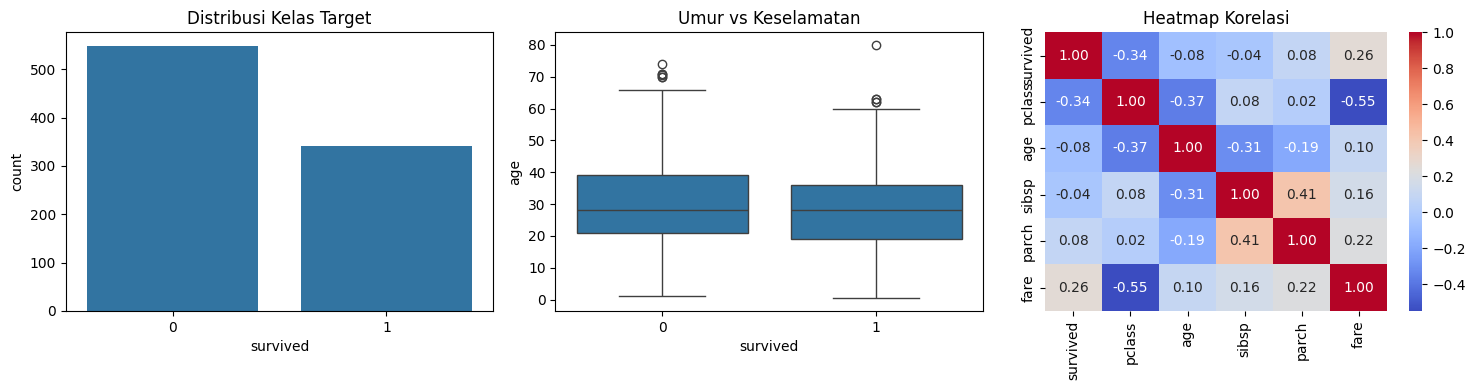


--- Model Logistic Regression ---
      Fitur  Koefisien
0    pclass  -0.996456
1       age  -0.502452
2      fare   0.189417
3     sibsp  -0.265403
4     parch  -0.107772
5  sex_male  -2.550358

Interpretasi: Koefisien negatif (misal sex_male) mengurangi peluang selamat (kelas 1). Koefisien pclass yang membesar (kelas lebih rendah) juga menekan peluang selamat.

--- Evaluasi Klasifikasi ---
Accuracy : 0.80
Precision: 0.73
Recall   : 0.78
F1-Score : 0.76
ROC-AUC  : 0.85


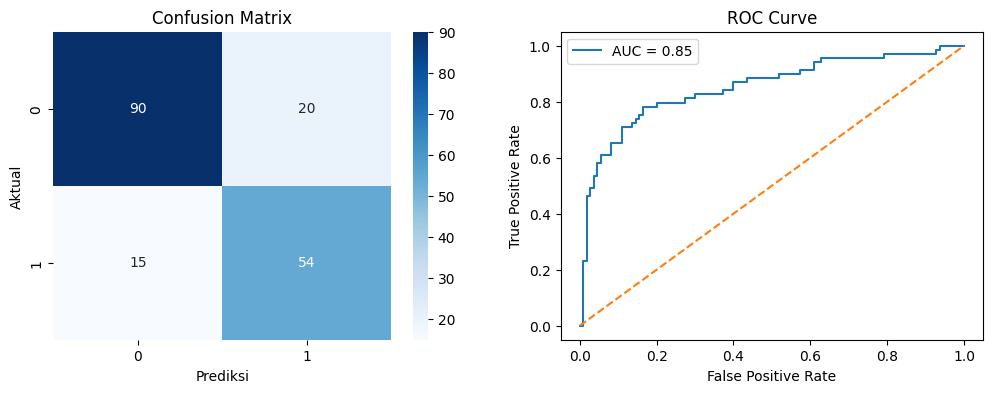

In [2]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, roc_auc_score, roc_curve

# B2. Eksplorasi dan Visualisasi Data
df_titanic = sns.load_dataset('titanic')

plt.figure(figsize=(15, 4))
# 1. Bar chart distribusi kelas
plt.subplot(1, 3, 1)
sns.countplot(x='survived', data=df_titanic)
plt.title('Distribusi Kelas Target')

# 2. Box plot fitur numerik per kelas
plt.subplot(1, 3, 2)
sns.boxplot(x='survived', y='age', data=df_titanic)
plt.title('Umur vs Keselamatan')

# 3. Heatmap
plt.subplot(1, 3, 3)
sns.heatmap(df_titanic.select_dtypes(include=np.number).corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Heatmap Korelasi')
plt.tight_layout()
plt.show()

# B3 & B4. Preprocessing & Pemilihan Fitur
# Memilih fitur yang relevan secara logika dan korelasi
features = ['pclass', 'sex', 'age', 'fare', 'sibsp', 'parch', 'survived']
df_t = df_titanic[features].copy()

# Mengisi missing values (Umur diisi dengan median)
df_t['age'] = df_t['age'].fillna(df_t['age'].median())

# Encoding categorical (sex)
df_t = pd.get_dummies(df_t, drop_first=True)

X_log = df_t.drop('survived', axis=1)
y_log = df_t['survived']

# Scaling fitur numerik (wajib untuk logreg agar konvergen)
scaler_log = StandardScaler()
X_log[['age', 'fare']] = scaler_log.fit_transform(X_log[['age', 'fare']])

# B5. Pembagian Data (Stratify sangat penting untuk klasifikasi)
X_train_l, X_test_l, y_train_l, y_test_l = train_test_split(
    X_log, y_log, test_size=0.2, random_state=42, stratify=y_log
)

# B6. Pemodelan (Class weight balanced jika kelas agak timpang)
model_log = LogisticRegression(class_weight='balanced')
model_log.fit(X_train_l, y_train_l)

print("\n--- Model Logistic Regression ---")
coef_log = pd.DataFrame({'Fitur': X_log.columns, 'Koefisien': model_log.coef_[0]})
print(coef_log)
print("\nInterpretasi: Koefisien negatif (misal sex_male) mengurangi peluang selamat (kelas 1). Koefisien pclass yang membesar (kelas lebih rendah) juga menekan peluang selamat.")

# B7. Evaluasi
y_pred_l = model_log.predict(X_test_l)
y_proba_l = model_log.predict_proba(X_test_l)[:, 1]

print("\n--- Evaluasi Klasifikasi ---")
print(f"Accuracy : {accuracy_score(y_test_l, y_pred_l):.2f}")
print(f"Precision: {precision_score(y_test_l, y_pred_l):.2f}")
print(f"Recall   : {recall_score(y_test_l, y_pred_l):.2f}")
print(f"F1-Score : {f1_score(y_test_l, y_pred_l):.2f}")
print(f"ROC-AUC  : {roc_auc_score(y_test_l, y_proba_l):.2f}")

# Visualisasi Confusion Matrix & ROC
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
sns.heatmap(confusion_matrix(y_test_l, y_pred_l), annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix'); plt.xlabel('Prediksi'); plt.ylabel('Aktual')

plt.subplot(1, 2, 2)
fpr, tpr, _ = roc_curve(y_test_l, y_proba_l)
plt.plot(fpr, tpr, label=f'AUC = {roc_auc_score(y_test_l, y_proba_l):.2f}')
plt.plot([0, 1], [0, 1], linestyle='--')
plt.title('ROC Curve')
plt.xlabel('False Positive Rate'); plt.ylabel('True Positive Rate')
plt.legend()
plt.show()

## B8. Analisis Performa
* **Metrik Paling Relevan:** Dalam kasus evakuasi nyawa (seperti Titanic), metrik **Recall** sangat penting karena kita ingin meminimalisir *False Negative* (model memprediksi tidak selamat, padahal sebenarnya dia bisa selamat jika diselamatkan).
* **Jenis Kesalahan Sering Terjadi:** Berdasarkan *Confusion Matrix*, kesalahan model didistribusikan. Karena menggunakan `class_weight='balanced'`, model menjadi lebih sensitif untuk memprediksi kelas 1 (selamat), sehingga sering terjadi *False Positive* (memprediksi selamat, padahal aktualnya tidak).
* **Keterbatasan:** Fitur yang ada cukup sederhana. Model logistik hanya menangkap pola linier terhadap probabilitas log-odds, jika ada kaitan non-linier antara batas usia dan keselamatan, model ini tidak dapat menangkapnya secara sempurna.